In [520]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import os

In [521]:
# print (os.getcwd())
# print (os.listdir())
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

## 1- Exploring Data

In [522]:
print ("head of data\n", train.head())
print ("tail of data\n", train.tail())
print ("sample of data\n", train.sample())

head of data
    PassengerId  Survived  Pclass                                               Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
0            1         0       3                            Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
1            2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0          PC 17599  71.2833   C85        C
2            3         1       3                             Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
3            4         1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
4            5         0       3                           Allen, Mr. William Henry    male  35.0      0      0            373450   8.0500   NaN        S
tail of data
      PassengerId  Survived  Pclass              

In [523]:
train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'], dtype='str')

In [524]:
train.info

<bound method DataFrame.info of      PassengerId  Survived  Pclass                                               Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
0              1         0       3                            Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
1              2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0          PC 17599  71.2833   C85        C
2              3         1       3                             Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
3              4         1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
4              5         0       3                           Allen, Mr. William Henry    male  35.0      0      0            373450   8.0500   NaN        S
..           ...       ...     .

In [525]:
train.shape

(891, 12)

In [526]:
train.describe

<bound method DataFrame.describe of      PassengerId  Survived  Pclass                                               Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
0              1         0       3                            Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
1              2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1      0          PC 17599  71.2833   C85        C
2              3         1       3                             Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
3              4         1       1       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
4              5         0       3                           Allen, Mr. William Henry    male  35.0      0      0            373450   8.0500   NaN        S
..           ...       ...  

In [527]:

train.isnull()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


In [528]:
null_values = train.isnull().sum()
print (null_values[null_values > 0])

Age         177
Cabin       687
Embarked      2
dtype: int64


<Axes: >

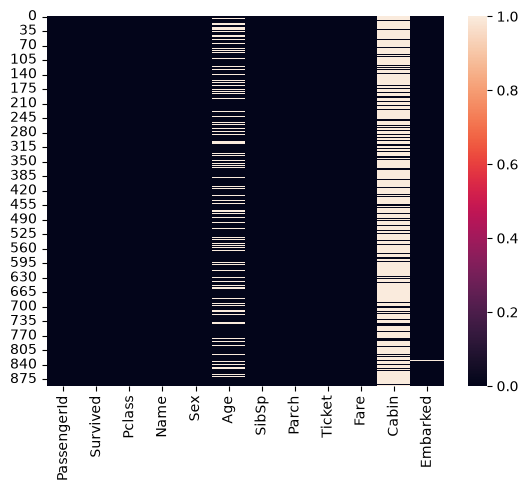

In [529]:
sns.heatmap(train.isnull())

## 2- Cleaning Data

In [530]:
def clean (d) :
    # drop the not needed columns
    d.drop(['Cabin', 'Name', 'Ticket', 'Embarked', 'Fare'], axis=1, inplace=True)
    # fill Age col with median value, because it so important and has a lot of missing values
    d.Age = d.Age.fillna(d.Age.median())
    # drop the rows with missing values
    d.dropna()
    return d

In [531]:
clean(train)

C:\Users\besha\AppData\Local\Temp\ipykernel_6168\3521721538.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  d.drop(['Cabin', 'Name', 'Ticket', 'Embarked', 'Fare'], axis=1, inplace=True)


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch
0,1,0,3,male,22.0,1,0
1,2,1,1,female,38.0,1,0
2,3,1,3,female,26.0,0,0
3,4,1,1,female,35.0,1,0
4,5,0,3,male,35.0,0,0
...,...,...,...,...,...,...,...
886,887,0,2,male,27.0,0,0
887,888,1,1,female,19.0,0,0
888,889,0,3,female,28.0,1,2
889,890,1,1,male,26.0,0,0


<Axes: >

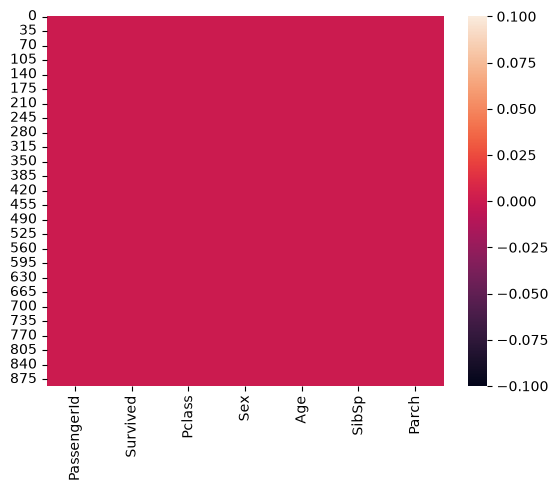

In [532]:
sns.heatmap(train.isnull())

In [533]:
clean(test)
# test.columns

C:\Users\besha\AppData\Local\Temp\ipykernel_6168\3521721538.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  d.drop(['Cabin', 'Name', 'Ticket', 'Embarked', 'Fare'], axis=1, inplace=True)


,PassengerId,Pclass,Sex,Age,SibSp,Parch
0,892,3,male,34.5,0,0
1,893,3,female,47.0,1,0
2,894,2,male,62.0,0,0
3,895,3,male,27.0,0,0
4,896,3,female,22.0,1,1
...,...,...,...,...,...,...
413,1305,3,male,27.0,0,0
414,1306,1,female,39.0,0,0
415,1307,3,male,38.5,0,0
416,1308,3,male,27.0,0,0


<Axes: >

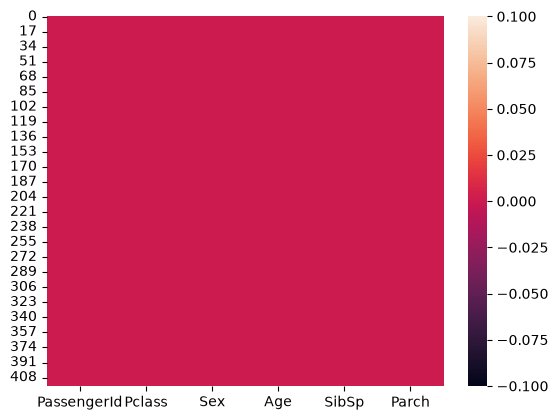

In [534]:
sns.heatmap(test.isnull())

In [535]:
train.Sex.value_counts()
train.Sex = train.Sex.map({'male': 1, 'female': 0})
test.Sex = test.Sex.map({'male': 1, 'female': 0})

## 3- Data Analysis

In [536]:
correlation = train.corr()
print (correlation)

             PassengerId  Survived    Pclass       Sex       Age     SibSp     Parch
PassengerId     1.000000 -0.005007 -0.035144  0.042939  0.034212 -0.057527 -0.001652
Survived       -0.005007  1.000000 -0.338481 -0.543351 -0.064910 -0.035322  0.081629
Pclass         -0.035144 -0.338481  1.000000  0.131900 -0.339898  0.083081  0.018443
Sex             0.042939 -0.543351  0.131900  1.000000  0.081163 -0.114631 -0.245489
Age             0.034212 -0.064910 -0.339898  0.081163  1.000000 -0.233296 -0.172482
SibSp          -0.057527 -0.035322  0.083081 -0.114631 -0.233296  1.000000  0.414838
Parch          -0.001652  0.081629  0.018443 -0.245489 -0.172482  0.414838  1.000000


<Axes: >

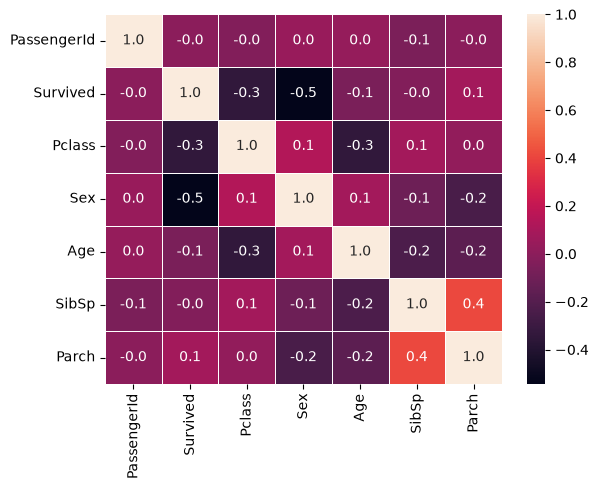

In [537]:
sns.heatmap(correlation, annot=True, fmt='.1f', linewidths=0.5)

In [538]:
train.Survived.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [539]:
train.Sex.value_counts()

Sex
1    577
0    314
Name: count, dtype: int64

<Axes: >

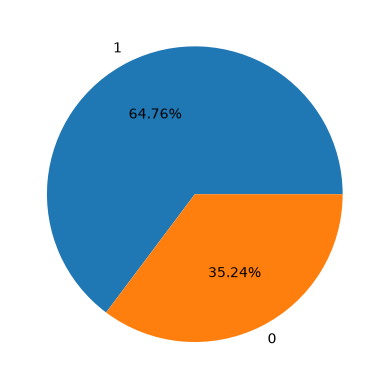

In [540]:
train.Sex.value_counts().plot.pie(autopct='%.2f%%')

<Axes: xlabel='Sex', ylabel='count'>

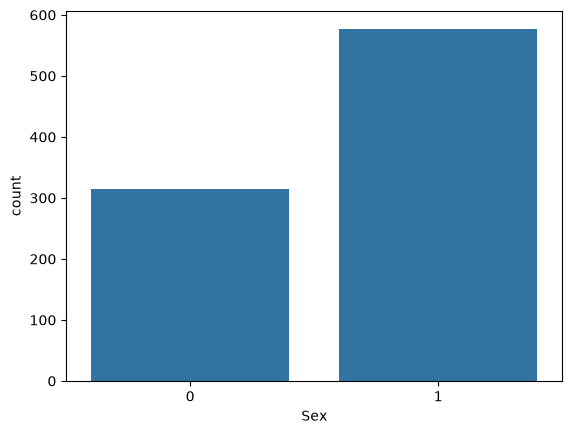

In [541]:
sns.countplot(x='Sex', data=train)

<Axes: xlabel='Sex', ylabel='count'>

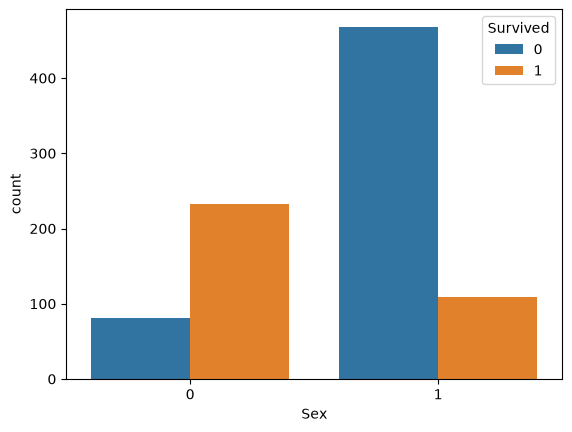

In [542]:
sns.countplot(x='Sex', data=train, hue='Survived')

<Axes: xlabel='Pclass', ylabel='count'>

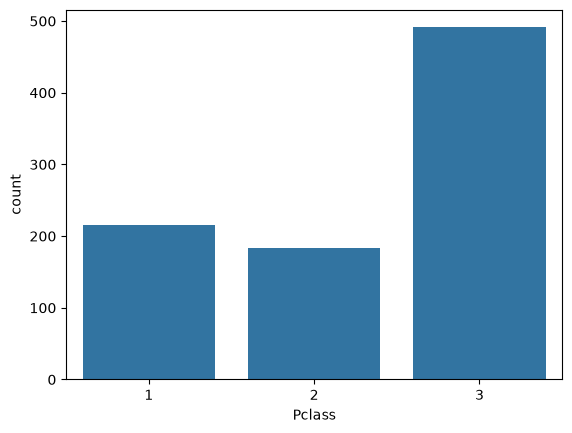

In [543]:
sns.countplot(x='Pclass', data=train)

<Axes: xlabel='Pclass', ylabel='count'>

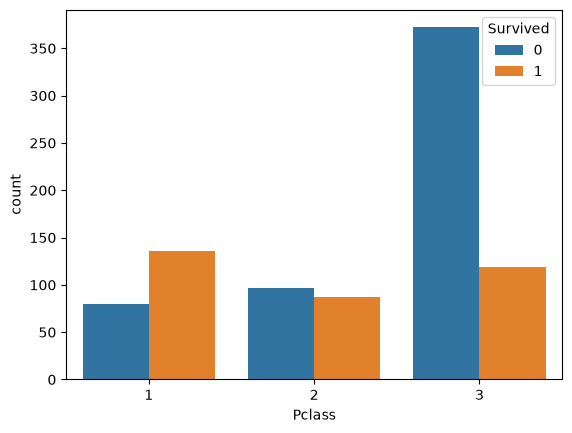

In [544]:
sns.countplot(x='Pclass', data=train, hue='Survived')

<Axes: xlabel='Age', ylabel='Count'>

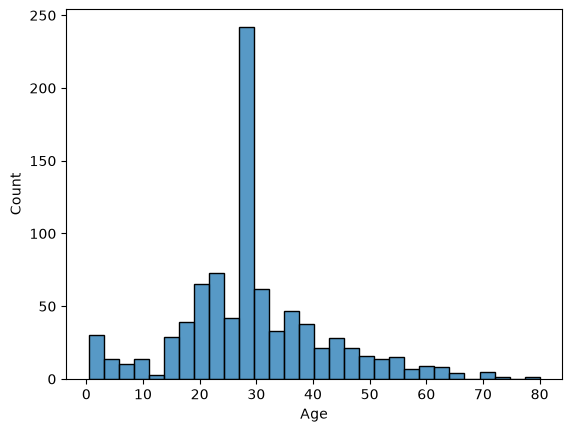

In [545]:
sns.histplot(x='Age', data=train)

<Axes: xlabel='Age', ylabel='Count'>

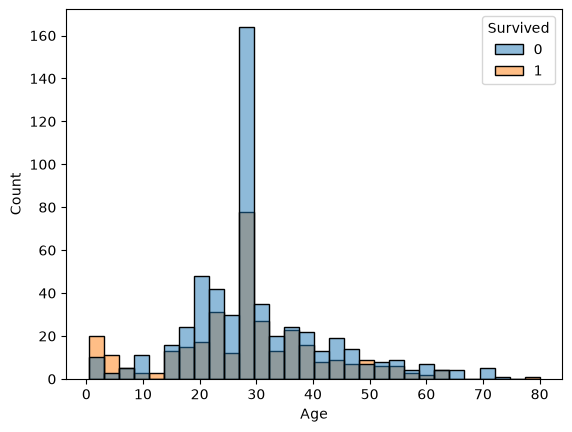

In [546]:
sns.histplot(x='Age', data=train, hue='Survived')

## 4- Create Model

In [547]:
x = train.drop(['Survived'], axis=1)
y = train.Survived

In [548]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [549]:
models = [LogisticRegression(), RandomForestClassifier(), GradientBoostingClassifier(), DecisionTreeClassifier(), KNeighborsClassifier(), GaussianNB(), SVC()]

In [550]:
accuracies = []

In [551]:
def allModels (model) :
    model.fit(x_train, y_train)
    model.predict(x_test)
    accuracy = model.score(x_test, y_test)
    accuracies.append(accuracy)


In [552]:
for model in range(len(models)):
    allModels(models[model])

c:\Users\besha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [553]:
print (accuracies)

[0.8100558659217877, 0.8156424581005587, 0.8156424581005587, 0.7039106145251397, 0.5251396648044693, 0.770949720670391, 0.5865921787709497]


In [556]:
modelResults = pd.DataFrame({'model': models, 'Accuracy': accuracies})
print (modelResults)

                          model  Accuracy
0          LogisticRegression()  0.810056
1      RandomForestClassifier()  0.815642
2  GradientBoostingClassifier()  0.815642
3      DecisionTreeClassifier()  0.703911
4        KNeighborsClassifier()  0.525140
5                  GaussianNB()  0.770950
6                         SVC()  0.586592


In [566]:
modelx = modelResults.sort_values(by='Accuracy', ascending=False).iloc[0]
best_model = modelx['model']
best_model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [567]:
lpre = best_model.predict(test)

In [569]:
final = test.PassengerId

In [576]:
newDf = pd.DataFrame({'PassengerId': final, 'Survived': lpre})
print (newDf.shape)
print (newDf.columns)
print (newDf.Survived.isna().sum())
print (newDf.Survived.unique())

(418, 2)
Index(['PassengerId', 'Survived'], dtype='str')
0
[0 1]


In [571]:
newDf_csv = newDf.to_csv('submission.csv', index=False)